<a href="https://colab.research.google.com/github/bimaadiwijaya8/-ML_05_Bima-Adiwijaya/blob/main/JS08/JS08-Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN          # butuh scikit-learn >= 1.3
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

print("Bentuk data:", X.shape)
print("Fitur      :", iris.feature_names)
print("Kelas asli :", list(iris.target_names))

Bentuk data: (150, 4)
Fitur      : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Kelas asli : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [3]:
X_scaled = StandardScaler().fit_transform(X)

In [4]:
hdb = HDBSCAN(min_cluster_size=5, copy=True)
labels = hdb.fit_predict(X_scaled)

In [5]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int(np.sum(labels == -1))

print(f"Jumlah cluster : {n_clusters}")
print(f"Jumlah noise   : {n_noise} dari {len(labels)} data")
print("Ukuran tiap cluster:", dict(zip(*np.unique(labels, return_counts=True))))

Jumlah cluster : 2
Jumlah noise   : 2 dari 150 data
Ukuran tiap cluster: {np.int64(-1): np.int64(2), np.int64(0): np.int64(50), np.int64(1): np.int64(98)}


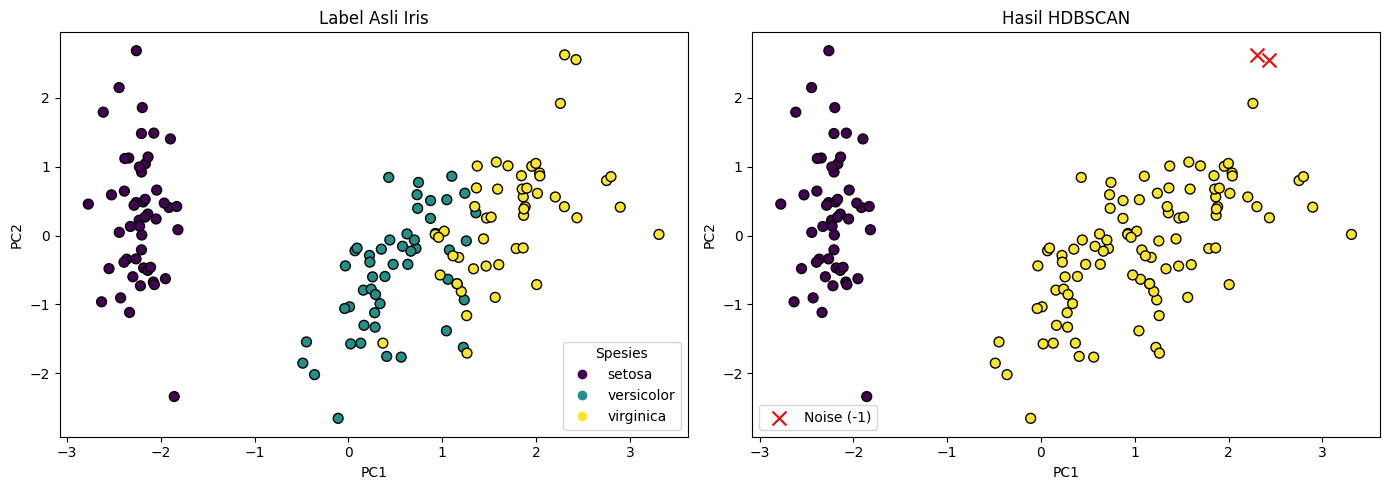

Varians dijelaskan PC1+PC2: 0.958


In [6]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Kiri: label asli
sc1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=50, edgecolor='k')
axes[0].set_title('Label Asli Iris')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
handles, _ = sc1.legend_elements()
axes[0].legend(handles, iris.target_names, title='Spesies')

# Kanan: hasil HDBSCAN (noise = silang merah)
mask = labels != -1
sc2 = axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], c=labels[mask],
                      cmap='viridis', s=50, edgecolor='k')
axes[1].scatter(X_pca[~mask, 0], X_pca[~mask, 1], c='red', marker='x', s=100, label='Noise (-1)')
axes[1].set_title('Hasil HDBSCAN')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Varians dijelaskan PC1+PC2:", pca.explained_variance_ratio_.sum().round(3))

In [7]:
# Tabel silang: baris = spesies asli, kolom = cluster HDBSCAN (-1 = noise)
ct = pd.crosstab(pd.Series(iris.target_names[y], name='Spesies asli'),
                 pd.Series(labels, name='Cluster HDBSCAN'))
display(ct)

ari = adjusted_rand_score(y, labels)
nmi = normalized_mutual_info_score(y, labels)
print(f"Adjusted Rand Index (ARI)      : {ari:.3f}")
print(f"Normalized Mutual Info (NMI)   : {nmi:.3f}")

Cluster HDBSCAN,-1,0,1
Spesies asli,,,
setosa,0,50,0
versicolor,0,0,50
virginica,2,0,48


Adjusted Rand Index (ARI)      : 0.564
Normalized Mutual Info (NMI)   : 0.717


## Analisis Hasil Clustering HDBSCAN pada Dataset Iris

### 1. Ringkasan Hasil
| Item | Hasil |
|---|---|
| Dataset | Iris (150 sampel, 4 fitur, 3 kelas asli) |
| Preprocessing | StandardScaler |
| Parameter | `min_cluster_size=5` |
| Jumlah cluster terbentuk | **2** |
| Jumlah noise | **2 data** (≈ 1,3% dari 150 data) |
| Adjusted Rand Index (ARI) | 0,564 |
| Normalized Mutual Information (NMI) | 0,717 |

### 2. Visualisasi
Visualisasi menggunakan PCA yang direduksi ke 2 dimensi. Data berdimensi 4 sehingga tidak dapat digambarkan langsung. Pada plot terlihat satu kelompok yang terpisah jelas dari data lain (setosa) dan satu kelompok besar yang menggabungkan dua spesies lainnya. Dua titik noise (tanda silang merah) berada di area perbatasan kelompok besar.

### 3. Apakah Hasil Sesuai Label Asli?
**Sebagian sesuai, tetapi tidak sepenuhnya.**

- **Setosa**: seluruh 50 sampel masuk ke satu cluster tersendiri. Cluster ini murni dan sesuai dengan label asli. Setosa memang terpisah jelas dari spesies lain pada ruang fitur.
- **Versicolor dan Virginica**: HDBSCAN menggabungkan keduanya ke dalam satu cluster (50 versicolor + 48 virginica). Dua sampel virginica dinyatakan noise.
- Akibatnya HDBSCAN hanya menemukan 2 cluster, sedangkan label asli berjumlah 3.

### 4. Penjelasan
HDBSCAN mendeteksi cluster berdasarkan **kepadatan data**, bukan berdasarkan label spesies. Versicolor dan virginica saling tumpang tindih (ada sampel yang berdekatan, tidak ada celah kepadatan rendah yang jelas di antara keduanya), sehingga dari sudut pandang kepadatan keduanya merupakan satu wilayah padat yang menyatu. Setosa terpisah oleh area berkepadatan rendah sehingga dikenali sebagai cluster sendiri.

Nilai ARI (0,564) dan NMI (0,717) bernilai sedang. Ini konsisten dengan temuan bahwa satu kelas terpisah sempurna, sedangkan dua kelas lainnya tidak terpisah.

### 5. Kesimpulan
HDBSCAN berhasil memisahkan setosa dengan sempurna dan mengidentifikasi 2 titik noise tanpa perlu menentukan jumlah cluster di awal. Namun, HDBSCAN tidak dapat membedakan versicolor dan virginica karena keduanya tumpang tindih secara kepadatan. Hal ini bukan berarti metode gagal. Ini menunjukkan bahwa struktur kepadatan alami pada Iris hanya terdiri dari 2 kelompok, walaupun terdapat 3 spesies secara biologis. Untuk memisahkan ketiga spesies, metode berbasis centroid (misalnya K-Means) atau pendekatan supervised lebih cocok.